In [1]:
import requests
import json
import matplotlib.pyplot as plt
video_id = "RwWx5pKS3eA"



get url!!!
get url finished!!!!!


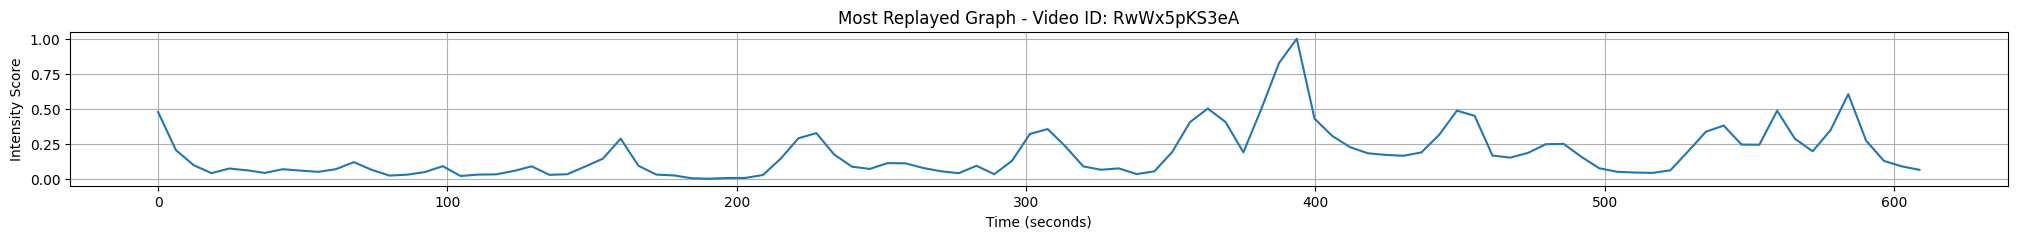

In [2]:

# API 엔드포인트 URL
url = f"https://yt.lemnoslife.com/videos?part=mostReplayed&id={video_id}"

# API 호출하여 JSON 데이터 가져오기
print('get url!!!')
response = requests.get(url)
print('get url finished!!!!!')
data = response.json()

# markers 리스트에서 startMillis와 intensityScoreNormalized 값 추출
markers = data['items'][0]['mostReplayed']['markers']
start_millis = [marker['startMillis'] for marker in markers]
intensity_scores = [marker['intensityScoreNormalized'] for marker in markers]

# 밀리초를 초로 변환
start_seconds = [millis / 1000 for millis in start_millis]

# 그래프 그리기
plt.figure(figsize=(25, 2))
plt.plot(start_seconds, intensity_scores)
plt.title(f'Most Replayed Graph - Video ID: {video_id}')
plt.xlabel('Time (seconds)')
plt.ylabel('Intensity Score')
plt.grid(True)
plt.show()

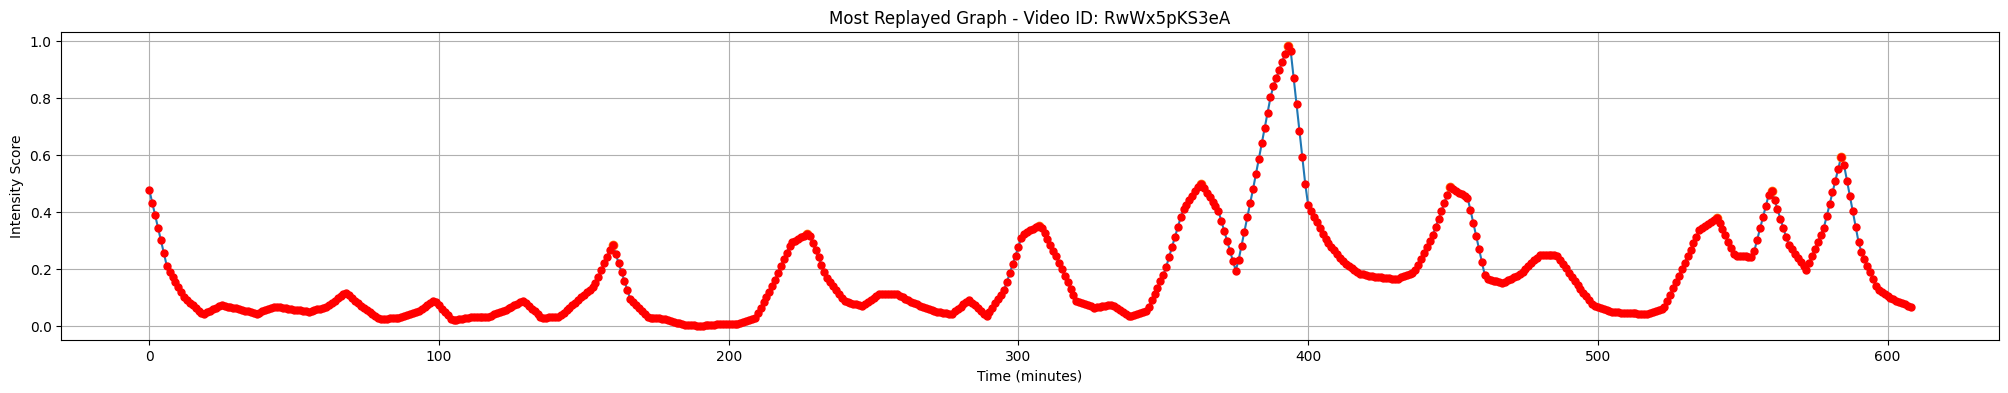

In [3]:
# 보간 함수 생성
from scipy.interpolate import interp1d
import numpy as np
from scipy.signal import find_peaks

interpolation_function = interp1d(start_seconds, intensity_scores, kind='linear', fill_value="extrapolate")

# 1초 간격으로 새로운 시간 생성
total_duration_seconds = start_seconds[-1]
new_time = np.arange(0, total_duration_seconds, 1)

# 새로운 시간에 대한 보간된 값 계산
smoothed_intensity_scores = interpolation_function(new_time)
peaks, _ = find_peaks(smoothed_intensity_scores, prominence = 0.1)

# 그래프 그리기
plt.figure(figsize=(25, 4))
plt.plot(new_time, smoothed_intensity_scores)  # 분으로 변환하여 표시
plt.plot(new_time[peaks], smoothed_intensity_scores[peaks], "o", label='Peaks')
plt.scatter(new_time, smoothed_intensity_scores, color='r', label='Selected Points', s=25, zorder=5)

plt.title(f'Most Replayed Graph - Video ID: {video_id}')
plt.xlabel('Time (minutes)')
plt.ylabel('Intensity Score')
plt.grid(True)
plt.show()

#  DP

In [4]:
total_time = 60

In [5]:
max_t = total_time
min_time = 3
scores = smoothed_intensity_scores


In [6]:
class State:
    def __init__(self, time, count, score):
        self.time = time
        self.count = count
        self.score = score
        self.frame = 0
        self.next_states = [] # 접근할 수 있는 인덱스 저장

    def get_info(self):
        # info = f'Peak: {self.peak}, Frame: {self.frame}, Count: {self.count}, Reward: {self.reward}, Time: {self.time}, Next State {self.next_states}'
        info = f'time: {self.time}, Count: {self.count},  Next State {self.next_states}'
        print(info)


In [7]:
states = [[State(time=i, count=j, score=scores[i]) for j in range(max_t + 1)] for i in range(len(scores))]


In [8]:
def set_next_states(states, min_time, max_t):
    n = len(states)
    for i in range(n):
        for t in range(max_t + 1):
            if i + 1 < n and t + 1 <= max_t :
                states[i][t].next_states.append((i + 1, t + 1))  # 다음 시간과 새로운 t 값
            if t >= min_time:
                for j in range(i + 2, n):
                    states[i][t].next_states.append((j, 0))  # 다음 상태의 인덱스와 새로운 t 값 0

In [9]:
set_next_states(states, min_time, max_t)

In [10]:
def DP(states, num_points):
    n = len(states)
    max_t = num_points
    dp = np.full((n, max_t + 1, num_points + 1), -np.inf)
    dp[:, 0, 0] = 0
    trace = np.full((n, max_t + 1, num_points + 1, 4), -1, dtype=int)

    for i in range(n):
        for t in range(max_t + 1):
            for k in range(1, num_points + 1):
                if dp[i, t, k - 1] != -np.inf:
                    for next_i, next_t in states[i][t].next_states:
                        if next_i < n and next_t <= max_t:
                            new_score = dp[i, t, k - 1] + states[next_i][next_t].score
                            if new_score > dp[next_i, next_t, k]:
                                dp[next_i, next_t, k] = new_score
                                trace[next_i, next_t, k] = (i, t, next_i, next_t)
    return dp, trace

def find_path(states, dp, trace, num_points):
    n = len(states)
    max_score = -np.inf
    max_index = (-1, -1, -1)
    for i in range(n):
        for t in range(num_points + 1):
            if dp[i, t, num_points] > max_score:
                max_score = dp[i, t, num_points]
                max_index = (i, t, num_points)

    selected_points = []
    k = num_points
    while max_index != (-1, -1, -1) and k > 0:
        max_index = tuple(trace[max_index[0], max_index[1], k])
        selected_points.append(max_index[0])
        k -= 1
    
    selected_points.reverse()
    return selected_points, max_score



In [11]:
def group_consecutive_points(points):
    grouped_points = []
    group = [points[0]]
    for i in range(1, len(points)):
        if points[i] == points[i-1] + 1:
            group.append(points[i])
        else:
            grouped_points.append(group)
            group = [points[i]]
    grouped_points.append(group)
    return grouped_points

# threshold

In [12]:
def find_intervals(smoothed_intensity_scores, a):
    time = np.arange(len(smoothed_intensity_scores))
    above_threshold = smoothed_intensity_scores > a
    changes = np.diff(above_threshold.astype(int))
    
    starts = time[1:][changes == 1]
    ends = time[1:][changes == -1]
    
    if above_threshold[0]:
        starts = np.insert(starts, 0, 0)
    if above_threshold[-1]:
        ends = np.append(ends, len(time) - 1)
    
    intervals = list(zip(starts, ends))
    total_time = sum(end - start for start, end in intervals)
    
    return total_time, intervals

def find_closest_intervals(smoothed_intensity_scores, t):
    lst = np.linspace(0, 1, 100)
    closest_diff = float('inf')
    threshold = None
    best_total_time = None
    best_intervals = None
    
    for a in lst:
        total_time, intervals = find_intervals(smoothed_intensity_scores, a)
        diff = abs(total_time - t)
        if diff < closest_diff:
            closest_diff = diff
            threshold = a
            best_total_time = total_time
            best_intervals = intervals
    
    return threshold, best_total_time, best_intervals



# Knapsack

In [13]:
def knapSack(W, wt, val, n):
	""" Maximize the value that a knapsack of capacity W can hold. You can either put the item or discard it, there is
	no concept of putting some part of item in the knapsack.

	:param int W: Maximum capacity -in frames- of the knapsack.
	:param list[int] wt: The weights (lengths -in frames-) of each video shot.
	:param list[float] val: The values (importance scores) of each video shot.
	:param int n: The number of the shots.
	:return: A list containing the indices of the selected shots.
	"""
	K = [[0 for _ in range(W + 1)] for _ in range(n + 1)]

	# Build table K[][] in bottom up manner
	for i in range(n + 1):
		for w in range(W + 1):
			if i == 0 or w == 0:
				K[i][w] = 0
			elif wt[i - 1] <= w:
				K[i][w] = max(val[i - 1] + K[i - 1][w - wt[i - 1]], K[i - 1][w])
			else:
				K[i][w] = K[i - 1][w]

	selected = []
	w = W
	for i in range(n, 0, -1):
		if K[i][w] != K[i - 1][w]:
			selected.insert(0, i - 1)
			w -= wt[i - 1]

	return selected

def merge_intervals(intervals):
    if not intervals:
        return []
    
    sorted_intervals = sorted(intervals, key=lambda x: x[0])
    merged = []
    for interval in sorted_intervals:
        if not merged or interval[0] > merged[-1][1] + 1:
            merged.append(interval)
        else:
            merged[-1] = (merged[-1][0], max(merged[-1][1], interval[1]))
    
    return merged

def generate_summary(smoothed_intensity_scores, new_time, segment_length, time):
    n_frames = len(smoothed_intensity_scores)
    segment_frames = int(segment_length * (n_frames / new_time[-1]))
    n_segments = n_frames // segment_frames
    segments = np.array_split(smoothed_intensity_scores, n_segments)
    
    segment_scores = [segment.mean() for segment in segments]
    segment_lengths = [len(segment) for segment in segments]
    picks = knapSack(time, segment_lengths, segment_scores, n_segments)
    
    selected_intervals = []
    for pick in sorted(picks):
        start = pick * segment_frames
        end = min((pick + 1) * segment_frames, n_frames)
        selected_intervals.append((new_time[start], new_time[end - 1]))
    
    return merge_intervals(selected_intervals)



# Plot

In [14]:
import numpy as np
import matplotlib.pyplot as plt

def plot_summaries(new_time, smoothed_intensity_scores, dp_intervals, threshold_intervals, knapsack_intervals):
    fig, axs = plt.subplots(3, 1, figsize=(12, 6), sharex=True)
    methods = ['DP Method', 'Threshold Method', 'Knapsack Method']
    intervals_list = [dp_intervals, threshold_intervals, knapsack_intervals]

    for ax, method, intervals in zip(axs, methods, intervals_list):
        ax.plot(new_time, smoothed_intensity_scores,)
        
        total_duration = 0
        for start, end in intervals:
            start, end = int(start), int(end)
            ax.plot(new_time[start:end+1], smoothed_intensity_scores[start:end+1], color='red', linewidth=2)
            duration = end - start + 1
            total_duration += duration 
            mid_point = (start + end) // 2
            ax.text(new_time[mid_point], smoothed_intensity_scores[mid_point], 
                     f'{duration}s', color='black', fontweight='bold', fontsize=20,
                     ha='center', va='bottom')

        ax.set_title(f'{method} (Total Duration: {total_duration}s)')
        ax.set_ylabel('Intensity Score')
        ax.grid(True)
        ax.legend()

    axs[-1].set_xlabel('Time (seconds)')
    plt.tight_layout()
    plt.show()



# 그래프 그리기


In [15]:
# DP
dp, trace = DP(states, num_points=total_time)
selected_points, max_score = find_path(states, dp, trace, num_points=total_time)

grouped_points = group_consecutive_points(selected_points)
dp_intervals = [(group[0], group[-1]) for group in grouped_points]

In [16]:
len(selected_points)

60

In [17]:




# threshold
threshold, total_time, threshold_intervals = find_closest_intervals(smoothed_intensity_scores, total_time)


# knapsack
segment_length = 5
knapsack_intervals = generate_summary(smoothed_intensity_scores, new_time, segment_length, time=total_time)


In [18]:
knapsack_intervals

[(355.0, 364.0),
 (375.0, 399.0),
 (445.0, 449.0),
 (555.0, 559.0),
 (575.0, 584.0)]

C:\Users\vml_sub\AppData\Local\Temp\ipykernel_386200\1652311309.py:26: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


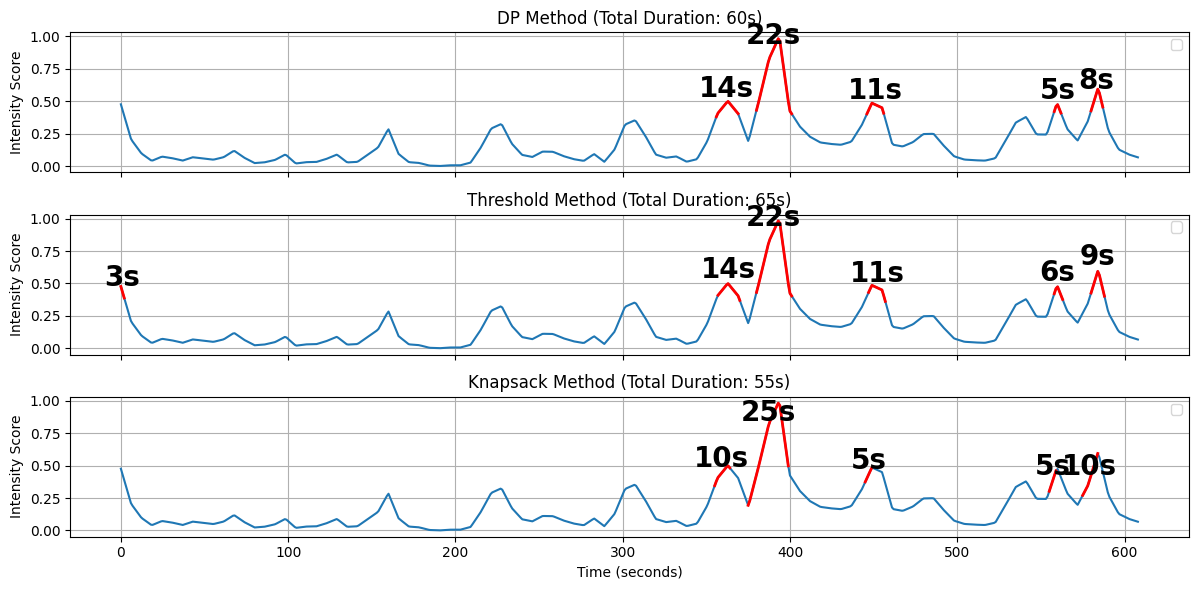

In [19]:
plot_summaries(new_time, smoothed_intensity_scores, dp_intervals, threshold_intervals, knapsack_intervals)